## CL-2 (BI) Assignment 4: Molecular Docking and Virtual Screening
### Perform a molecular docking and virtual-screening workflow to predict interactions between a protein target and small-molecule ligands.

In [1]:
# ------------------------------------------------------------
# PACKAGES REQUIRED: numpy pandas matplotlib rdkit
# If any package is not available (ModuleNotFoundError),
# uncomment the line below, run this cell once, then restart the kernel.
# ------------------------------------------------------------
# %pip install numpy pandas matplotlib rdkit
# OPTIONAL (only for the last cell - real docking with AutoDock Vina):
# Vina is NOT needed for the program to run; without it the last cell just prints a message.
# %pip install vina

In [2]:
import os, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt
try:
    from rdkit import Chem
    from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors
    RDKIT_AVAILABLE=True
    print("RDKit available")
except ImportError:
    RDKIT_AVAILABLE=False
    print("RDKit not installed. Install with: conda install -c conda-forge rdkit")

RDKit available


In [3]:
ligands_df=pd.DataFrame({
    "Molecule_ID":["Ligand_01","Ligand_02","Ligand_03","Ligand_04","Ligand_05","Ligand_06"],
    "SMILES":["CCO","CC(=O)Oc1ccccc1C(=O)O","CCN(CC)CC","c1ccccc1",
              "CC(C)Cc1ccc(cc1)C(C)C(=O)O","CCOC(=O)c1ccccc1"]
})
display(ligands_df)

,Molecule_ID,SMILES
0,Ligand_01,CCO
1,Ligand_02,CC(=O)Oc1ccccc1C(=O)O
2,Ligand_03,CCN(CC)CC
3,Ligand_04,c1ccccc1
4,Ligand_05,CC(C)Cc1ccc(cc1)C(C)C(=O)O
5,Ligand_06,CCOC(=O)c1ccccc1


In [4]:
if RDKIT_AVAILABLE:
    rows=[]
    for _,r in ligands_df.iterrows():
        m=Chem.MolFromSmiles(r.SMILES)
        if m:
            rows.append({
                "Molecule_ID":r.Molecule_ID,"SMILES":r.SMILES,
                "MolWt":Descriptors.MolWt(m),"LogP":Crippen.MolLogP(m),
                "HBD":Lipinski.NumHDonors(m),"HBA":Lipinski.NumHAcceptors(m),
                "TPSA":rdMolDescriptors.CalcTPSA(m),
                "RotatableBonds":Lipinski.NumRotatableBonds(m)})
    desc=pd.DataFrame(rows)
    display(desc)
    filtered=desc[(desc.MolWt<=500)&(desc.LogP<=5)&(desc.HBD<=5)&(desc.HBA<=10)]
    print("Candidates passing basic filter:",len(filtered),"/",len(desc))
    display(filtered)
else:
    print("Install RDKit to run descriptor calculations.")

,Molecule_ID,SMILES,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds
0,Ligand_01,CCO,46.069,-0.0014,1,1,20.23,0
1,Ligand_02,CC(=O)Oc1ccccc1C(=O)O,180.159,1.3101,1,3,63.60,2
2,Ligand_03,CCN(CC)CC,101.193,1.3481,0,1,3.24,3
3,Ligand_04,c1ccccc1,78.114,1.6866,0,0,0.00,0
4,Ligand_05,CC(C)Cc1ccc(cc1)C(C)C(=O)O,206.285,3.0732,1,1,37.30,4
5,Ligand_06,CCOC(=O)c1ccccc1,150.177,1.8633,0,2,26.30,2


Candidates passing basic filter: 6 / 6


,Molecule_ID,SMILES,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds
0,Ligand_01,CCO,46.069,-0.0014,1,1,20.23,0
1,Ligand_02,CC(=O)Oc1ccccc1C(=O)O,180.159,1.3101,1,3,63.60,2
2,Ligand_03,CCN(CC)CC,101.193,1.3481,0,1,3.24,3
3,Ligand_04,c1ccccc1,78.114,1.6866,0,0,0.00,0
4,Ligand_05,CC(C)Cc1ccc(cc1)C(C)C(=O)O,206.285,3.0732,1,1,37.30,4
5,Ligand_06,CCOC(=O)c1ccccc1,150.177,1.8633,0,2,26.30,2


,Molecule_ID,Descriptor_Distance,Screening_Score
0,Ligand_01,0.000000,1.000000
3,Ligand_04,1.246478,0.445141
2,Ligand_03,1.394593,0.417607
1,Ligand_02,1.428939,0.411702
5,Ligand_06,1.469790,0.404893
4,Ligand_05,1.752723,0.363277


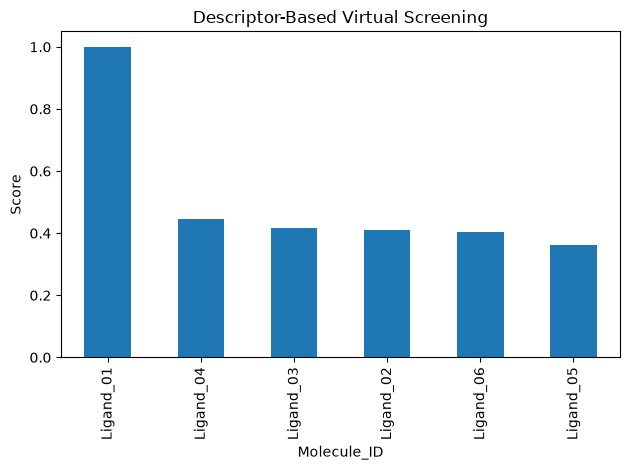

In [5]:
if RDKIT_AVAILABLE:
    ref=desc.iloc[0]
    cols=["MolWt","LogP","HBD","HBA","TPSA","RotatableBonds"]
    scale=(desc[cols].max()-desc[cols].min()).replace(0,1)
    d=[]
    for _,r in desc.iterrows():
        d.append(np.sqrt(np.sum(((r[cols].astype(float)-ref[cols].astype(float))/scale)**2)))
    desc["Descriptor_Distance"]=d
    desc["Screening_Score"]=1/(1+desc.Descriptor_Distance)
    screening=desc.sort_values("Screening_Score",ascending=False)
    display(screening[["Molecule_ID","Descriptor_Distance","Screening_Score"]])
    screening.plot(x="Molecule_ID",y="Screening_Score",kind="bar",legend=False)
    plt.title("Descriptor-Based Virtual Screening"); plt.ylabel("Score"); plt.tight_layout(); plt.show()

In [6]:
vina=shutil.which("vina")
receptor="receptor.pdbqt"; ligand="ligand_01.pdbqt"
center_x,center_y,center_z=0.0,0.0,0.0
size_x,size_y,size_z=20.0,20.0,20.0
print("Vina:",vina or "NOT FOUND")
if vina and os.path.exists(receptor) and os.path.exists(ligand):
    cmd=[vina,"--receptor",receptor,"--ligand",ligand,
         "--center_x",str(center_x),"--center_y",str(center_y),"--center_z",str(center_z),
         "--size_x",str(size_x),"--size_y",str(size_y),"--size_z",str(size_z),
         "--out","docked_ligand.pdbqt","--log","docking.log"]
    print("Ready to execute:")
    print(" ".join(cmd))
else:
    print("Provide prepared PDBQT files, docking-box values, and AutoDock Vina to perform real docking.")

Vina: NOT FOUND
Provide prepared PDBQT files, docking-box values, and AutoDock Vina to perform real docking.
